## 3.1 — Data pipeline verification

Load `data_set_split/` via `train_classifier.py`'s pipeline.
Confirm: shapes, class mapping, augmentation applied only to train.

Found 4026 files belonging to 4 classes.
Found 511 files belonging to 4 classes.
Found 711 files belonging to 4 classes.
Train batch: (32, 224, 224, 3) | labels: [3 2 3 3 0 3 3 3]
Image dtype: <dtype: 'float32'>, range: [0.00, 255.00]
Class order : ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


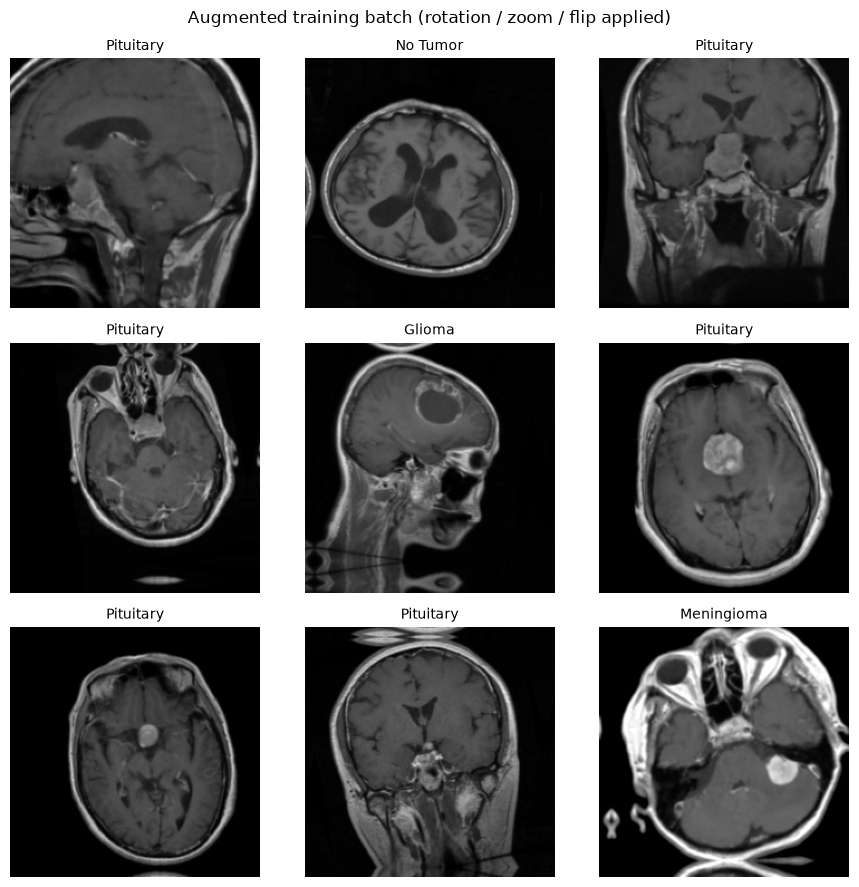

In [3]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt
from train_classifier import get_datasets, CLASSES, IMG_SIZE, BATCH_SIZE, build_augmentation

train_ds, val_ds, test_ds = get_datasets()

xb, yb = next(iter(train_ds))
print(f"Train batch: {xb.shape} | labels: {yb.numpy()[:8]}")
print(f"Image dtype: {xb.dtype}, range: [{xb.numpy().min():.2f}, {xb.numpy().max():.2f}]")
print(f"Class order : {CLASSES}")

# EfficientNet: images are already in [0, 255] — display as-is
def show(img):
    return np.clip(img, 0, 255).astype("uint8")

# --- visual: 3x3 grid of augmented train images ---
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(show(xb[i].numpy()))
    ax.set_title(CLASSES[int(yb[i])], fontsize=10)
    ax.axis("off")
plt.suptitle("Augmented training batch (rotation / zoom / flip applied)", fontsize=12)
plt.tight_layout(); plt.show()

Found 4026 files belonging to 4 classes.


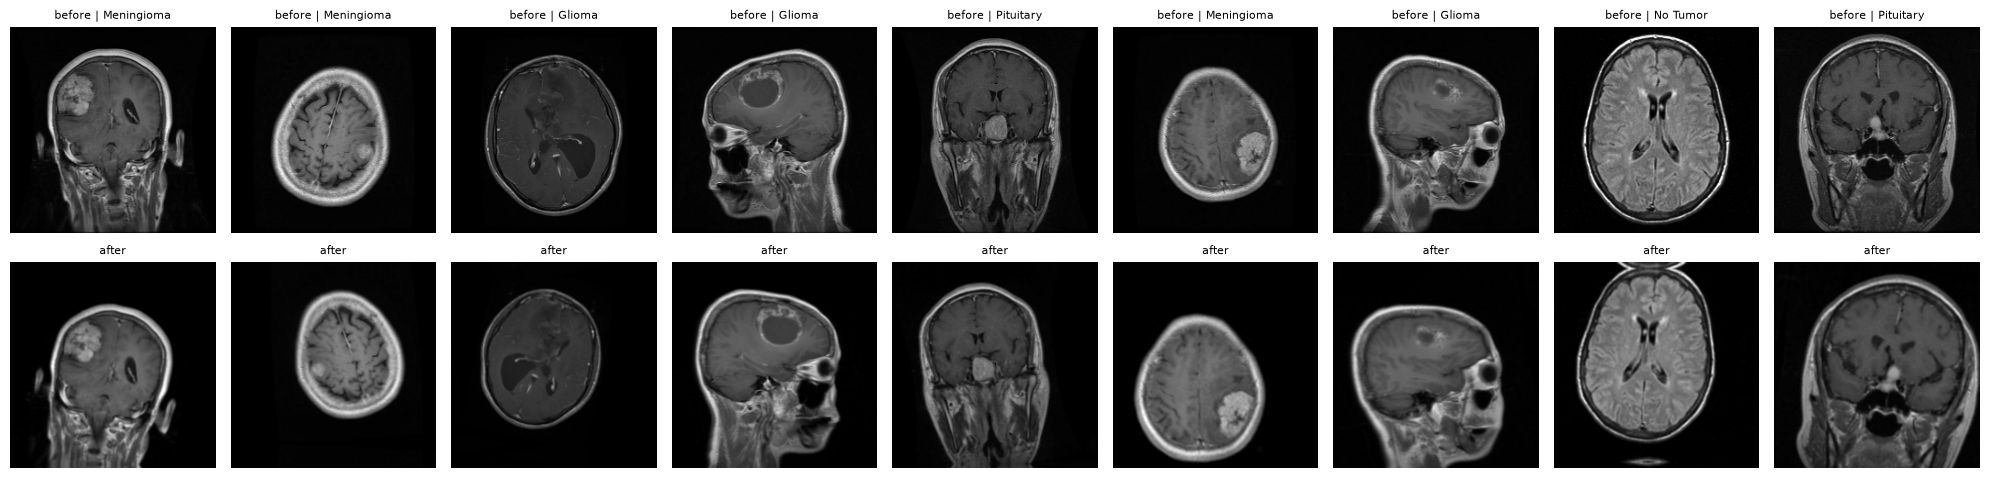

In [4]:
# Raw dataset (no augmentation, no preprocess) — reload one batch from source


import tensorflow as tf
raw = tf.keras.utils.image_dataset_from_directory(
    Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\data_set_split\train"),
    image_size=IMG_SIZE, batch_size=9, shuffle=True, seed=0, labels="inferred",
    label_mode="int", class_names=CLASSES,
)
xr, yr = next(iter(raw))

# Apply same augmentation pipeline once
aug = build_augmentation()
xa = aug(xr, training=True)

fig, axes = plt.subplots(2, 9, figsize=(20, 5))
for i in range(9):
    axes[0, i].imshow(xr[i].numpy().astype("uint8"))
    axes[0, i].set_title(f"before | {CLASSES[int(yr[i])]}", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(show(xa[i].numpy()))
    axes[1, i].set_title("after", fontsize=8)
    axes[1, i].axis("off")
plt.tight_layout(); plt.show()

## 3.2 — Model verification

Build the model for each mode, confirm param counts and layer freeze state.

In [5]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

from train_classifier import (
    get_datasets, build_model, compute_class_weights, get_callbacks,
    CLASSES, MODELS_DIR,
)

# Build both modes to compare
m_frozen    = build_model("frozen")
m_finetuned = build_model("finetuned")

def summary_line(m, name):
    total = m.count_params()
    trainable = sum(
        tf.keras.backend.count_params(w)
        for w in m.trainable_weights
    )
    print(f"{name:10s} | total: {total:>9,} | trainable: {trainable:>9,} | "
          f"frozen: {total - trainable:>9,}")

import tensorflow as tf
summary_line(m_frozen,    "frozen")
summary_line(m_finetuned, "finetuned")

# Class weights + distribution
train_ds, val_ds, test_ds = get_datasets()
weights, counts = compute_class_weights(train_ds)
print("\nClass weights (higher = more compensation):")
for i, c in enumerate(CLASSES):
    print(f"  {i} {c:12s} | count: {counts[i]:5d} | weight: {weights[i]:.3f}")

# Confirm callbacks return 3 items + checkpoint path
cbs, ckpt = get_callbacks("frozen")
print(f"\nCallbacks: {[type(c).__name__ for c in cbs]}")
print(f"Checkpoint will save to: {ckpt}")

frozen     | total: 4,214,055 | trainable:   164,484 | frozen: 4,049,571
finetuned  | total: 4,214,055 | trainable: 3,243,616 | frozen:   970,439
Found 4026 files belonging to 4 classes.
Found 511 files belonging to 4 classes.
Found 711 files belonging to 4 classes.

Class weights (higher = more compensation):
  0 Glioma       | count:   979 | weight: 1.028
  1 Meningioma   | count:  1226 | weight: 0.821
  2 No Tumor     | count:   604 | weight: 1.666
  3 Pituitary    | count:  1217 | weight: 0.827

Callbacks: ['EarlyStopping', 'ModelCheckpoint', 'ReduceLROnPlateau']
Checkpoint will save to: C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\models\classifier_frozen.keras


In [7]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import importlib, train_classifier
importlib.reload(train_classifier)   # ensure we get the newest version

from train_classifier import get_datasets, build_model, get_callbacks

train_ds, val_ds, test_ds = get_datasets()
model = build_model("frozen")
cbs, _ = get_callbacks("frozen")

history = model.fit(
    train_ds.take(5), validation_data=val_ds.take(2),
    epochs=1, callbacks=cbs, verbose=1,
)
print("Smoke test OK.")

Found 4026 files belonging to 4 classes.
Found 511 files belonging to 4 classes.
Found 711 files belonging to 4 classes.
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 952ms/step - accuracy: 0.3250 - loss: 1.3761
Epoch 1: val_accuracy improved from None to 0.18750, saving model to C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\models\classifier_frozen.keras

Epoch 1: finished saving model to C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\models\classifier_frozen.keras
5/5 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.3250 - loss: 1.3761 - val_accuracy: 0.1875 - val_loss: 1.4587 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 1.
Smoke test OK.


## 3.5 — Model comparison: Frozen vs Fine-tuned

Compare the two training configurations produced by `src/train_classifier.py`.
Select the best model for deployment based on test-set metrics.

In [8]:
import json
from pathlib import Path
import pandas as pd

REPORTS = Path(r"C:\Users\ycode\Desktop\2nd_YouCode\briefs\MRI_class_DL\reports")

eval_frozen    = json.loads((REPORTS / "eval_frozen.json").read_text())
eval_finetuned = json.loads((REPORTS / "eval_finetuned.json").read_text())

history_frozen    = json.loads((REPORTS / "history_frozen.json").read_text())
history_finetuned = json.loads((REPORTS / "history_finetuned.json").read_text())

# ---- metrics comparison table ----
rows = []
for name, d in [("Frozen", eval_frozen), ("Fine-tuned", eval_finetuned)]:
    m = d["test_metrics"]
    rows.append({
        "Config": name,
        "Test Acc":   f"{m['accuracy']:.4f}",
        "Macro Prec": f"{m['macro_precision']:.4f}",
        "Macro Rec":  f"{m['macro_recall']:.4f}",
        "Macro F1":   f"{m['macro_f1']:.4f}",
        "Weighted F1":f"{m['weighted_f1']:.4f}",
        "Best Epochs": len(history_frozen["accuracy"] if name == "Frozen" else history_finetuned["accuracy"]),
    })

cmp_df = pd.DataFrame(rows)
display(cmp_df)

,Config,Test Acc,Macro Prec,Macro Rec,Macro F1,Weighted F1,Best Epochs
0,Frozen,0.8354,0.8482,0.8479,0.8393,0.8284,11
1,Fine-tuned,0.9170,0.9273,0.9238,0.9220,0.9154,19


In [9]:
classes = eval_frozen["class_order"]

rows = []
for c in classes:
    f = eval_frozen["per_class"][c]
    t = eval_finetuned["per_class"][c]
    rows.append({
        "Class": c,
        "Frozen Prec":    f"{f['precision']:.3f}",
        "Frozen Rec":     f"{f['recall']:.3f}",
        "Frozen F1":      f"{f['f1-score']:.3f}",
        "FT Prec":        f"{t['precision']:.3f}",
        "FT Rec":         f"{t['recall']:.3f}",
        "FT F1":          f"{t['f1-score']:.3f}",
        "Δ F1":           f"{t['f1-score'] - f['f1-score']:+.3f}",
    })
display(pd.DataFrame(rows))

,Class,Frozen Prec,Frozen Rec,Frozen F1,FT Prec,FT Rec,FT F1,Δ F1
0,Glioma,0.756,0.879,0.813,0.878,0.960,0.917,+0.104
1,Meningioma,0.873,0.606,0.716,0.966,0.787,0.867,+0.151
2,No Tumor,0.925,0.916,0.920,0.981,0.953,0.967,+0.047
3,Pituitary,0.839,0.991,0.908,0.884,0.995,0.937,+0.028


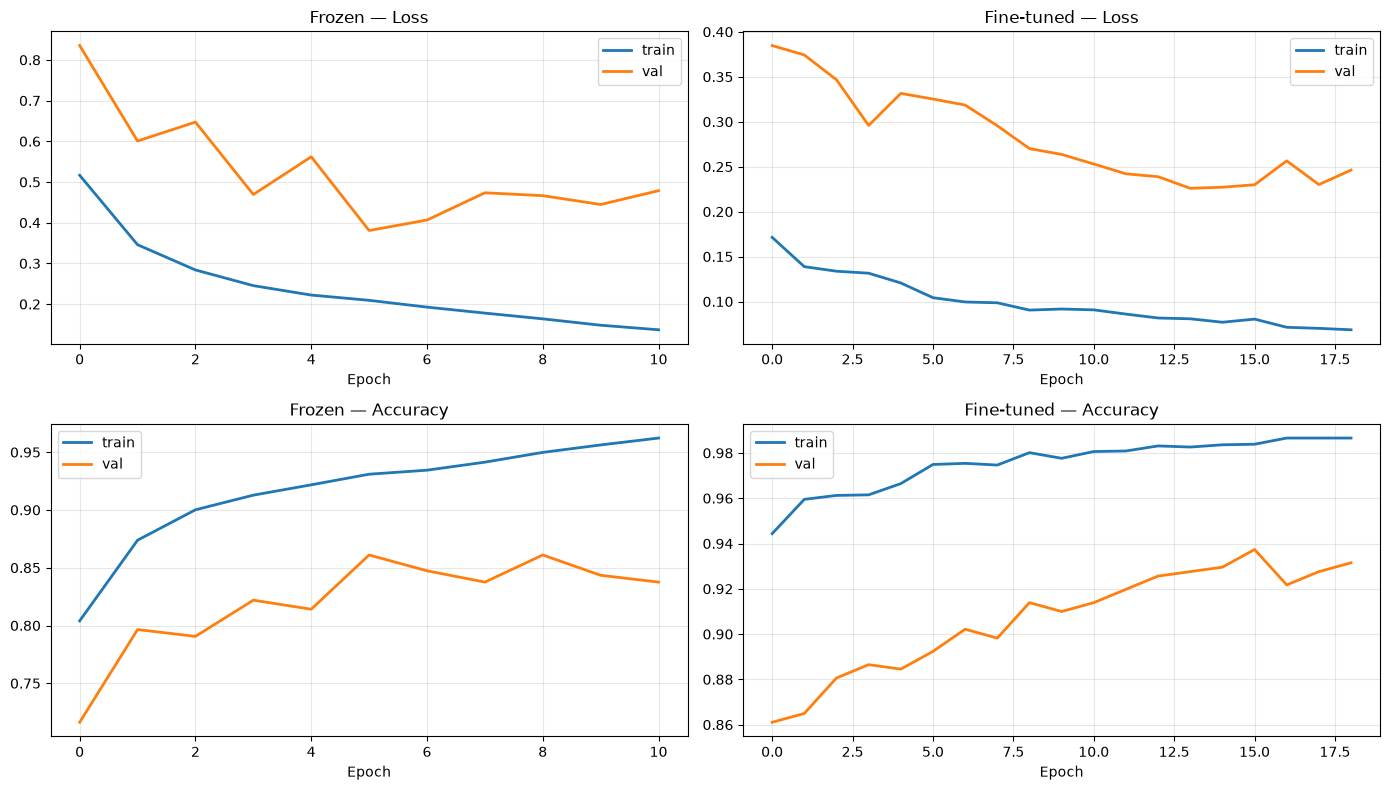

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Loss
axes[0,0].plot(history_frozen["loss"],     label="train", lw=2)
axes[0,0].plot(history_frozen["val_loss"], label="val",   lw=2)
axes[0,0].set_title("Frozen — Loss");      axes[0,0].set_xlabel("Epoch"); axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

axes[0,1].plot(history_finetuned["loss"],     label="train", lw=2)
axes[0,1].plot(history_finetuned["val_loss"], label="val",   lw=2)
axes[0,1].set_title("Fine-tuned — Loss");  axes[0,1].set_xlabel("Epoch"); axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

# Accuracy
axes[1,0].plot(history_frozen["accuracy"],     label="train", lw=2)
axes[1,0].plot(history_frozen["val_accuracy"], label="val",   lw=2)
axes[1,0].set_title("Frozen — Accuracy"); axes[1,0].set_xlabel("Epoch"); axes[1,0].legend(); axes[1,0].grid(alpha=0.3)

axes[1,1].plot(history_finetuned["accuracy"],     label="train", lw=2)
axes[1,1].plot(history_finetuned["val_accuracy"], label="val",   lw=2)
axes[1,1].set_title("Fine-tuned — Accuracy"); axes[1,1].set_xlabel("Epoch"); axes[1,1].legend(); axes[1,1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

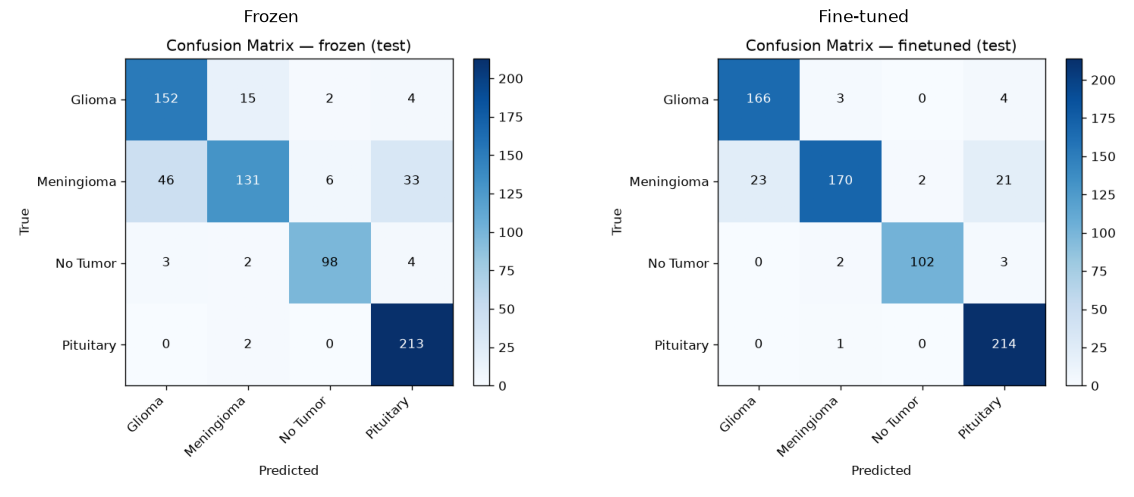

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(Image.open(REPORTS / "confusion_frozen.png"))
axes[0].set_title("Frozen"); axes[0].axis("off")
axes[1].imshow(Image.open(REPORTS / "confusion_finetuned.png"))
axes[1].set_title("Fine-tuned"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 3.6 — Step 3 findings & decision

### What we built
Two EfficientNet-B0 configurations trained on `data_set_split/` (4026 / 511 / 711):
- **Frozen**: backbone locked, only the classification head trained (165k params), LR=1e-3.
- **Fine-tuned**: top 30% of the backbone unfrozen, LR=1e-5, warm-started from Stage 1.

Both runs use:
- Augmentation: rotation ±15°, translation ±10%, zoom ±15°, contrast ±15%, horizontal flip
- Regularization: dropout 0.3 (x2), L2 1e-4
- Class weights: No Tumor 1.67, Meningioma 0.82 (balance for the 2:1 imbalance)
- Callbacks: EarlyStopping (patience 5), ModelCheckpoint, ReduceLROnPlateau

### Results

| Config | Test Acc | Macro Prec | Macro Rec | Macro F1 | Epochs |
|---|---|---|---|---|---|
| Frozen | 0.8354 | 0.8482 | 0.8479 | 0.8393 | 11 |
| **Fine-tuned** | **0.9170** | **0.9273** | **0.9238** | **0.9220** | 19 |

**Per class (F1):** Glioma 0.917, Meningioma 0.867, No Tumor 0.967, Pituitary 0.937.

### Overfitting analysis
- **Frozen**: clear overfitting. Train accuracy climbed to 0.96 while val plateaued at 0.86, and val loss rose after epoch 5. EarlyStopping restored epoch 6.
- **Fine-tuned**: mild, acceptable. Train 0.98 / val 0.94 gap (4 pp), test 0.917 (only 2 pp below val). Curves track together until epoch 14.
- Both models auto-stopped before max epochs — callbacks worked as designed.

### Decision
**Deploy the fine-tuned EfficientNet-B0.** +8.3 pp macro F1 over frozen, +15 pp Meningioma F1, balanced precision/recall (macro ≈ weighted), and the smallest train-val-test gap. Saved as `models/classifier_best.keras`.

### Files produced
- `models/classifier_frozen.keras` (baseline)
- `models/classifier_finetuned.keras` (winner)
- `models/classifier_best.keras` (deployment copy)
- `reports/eval_{frozen,finetuned}.json`
- `reports/history_{frozen,finetuned}.json`
- `reports/curves_{frozen,finetuned}.png`
- `reports/confusion_{frozen,finetuned}.png`
- `logs/train_{frozen,finetuned}_*.log`